# Iterated Weighted Least Squares for fitting GLMs
**Chris Hallsworth**


## Introduction
The aim of this tutorial is to understand the iterated weighted least squares (IWLS, also called IRLS) algorithm for fitting generalized linear models. For the Poisson model with its canonical log link, this is a repackaging of Newton's method.

We will see how the method gives us the Fisher information matrix, relate this to the asymptotic variance-covariance matrix of the maximum likelihood estimators, and explore when finite maximum likelihood estimators exist.

### Using this notebook
Run the cells in order. Tasks are followed by worked solutions; attempt each task before reading its solution. Incomplete exercise code appears in Markdown blocks so **Run All** executes the solutions without errors.

Dependencies: NumPy, pandas, Matplotlib, SciPy and statsmodels. If needed, run `%pip install numpy pandas matplotlib scipy statsmodels` in a new code cell. The simulation uses 10,000 fits and may take a little time.

The seed makes the Python results reproducible. NumPy and R use different random-number streams, so the simulated observations will differ from those in the R version.

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy.special import gammaln
from scipy.spatial import ConvexHull
from IPython.display import display

plt.rcParams.update({"figure.figsize": (7, 4.5), "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 11})
np.set_printoptions(precision=6, suppress=True)

## The model
We use a Poisson GLM with the canonical log link, fitted to simulated data. We keep the true parameters and means in separate variables so the fitting loop cannot overwrite them.

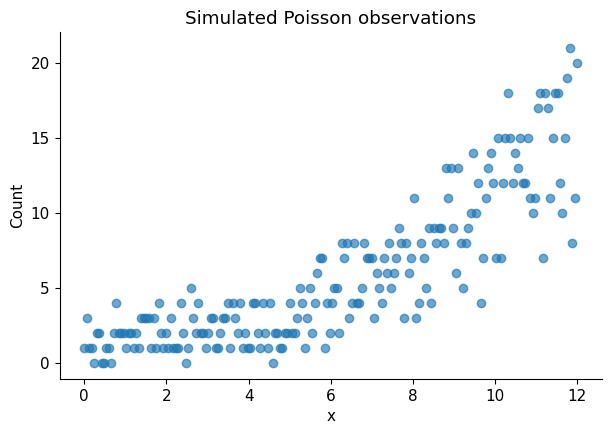

In [12]:
rng_data = np.random.default_rng(56)
n = 200
x = np.linspace(0, 12, n)
X = np.column_stack([np.ones(n), x])
beta_true = np.array([0.0, 0.24])
eta_true = X @ beta_true
mu_true = np.exp(eta_true)
y = rng_data.poisson(mu_true)
dat = pd.DataFrame({"x": x, "y": y})

fig, ax = plt.subplots()
ax.scatter(x, y, alpha=0.65)
ax.set(xlabel="x", ylabel="Count", title="Simulated Poisson observations")
plt.show()

## The idea of iterated weighted least squares
IWLS fits a succession of **general linear models**, using weighted linear regression.

For independent observations, the general linear model assumes
$$Y_i = X_i\beta + \epsilon_i, \qquad
\epsilon_i \sim N\left(0,\frac{\sigma^2}{w_i}\right).$$
For known weights, we minimise
$$\sum_{i=1}^n w_i(y_i-X_i\beta)^2.$$
Multiplying each response and row of the design matrix by $\sqrt{w_i}$ reduces this to ordinary least squares.

For the Poisson GLM, each IWLS step minimises a weighted least-squares criterion representing a local quadratic approximation to the negative log likelihood. The working responses and weights change at each step.

## Implementing IWLS
### Task 1
For the Poisson GLM with the log link, derive the adjusted dependent variable $z_i$ and the weights $w_{ii}$ in Algorithm 2.1 of the notes.

### Solution
Given a working estimate $\widehat\beta$, form
$$\widehat\eta_i=X_i\widehat\beta,\qquad
\widehat\mu_i=\exp(\widehat\eta_i).$$
The link is $g(\mu)=\log\mu$, with derivative $g'(\mu)=1/\mu$. Therefore
$$z_i=\widehat\eta_i+(y_i-\widehat\mu_i)g'(\widehat\mu_i)
=\widehat\eta_i+\frac{y_i-\widehat\mu_i}{\widehat\mu_i}.$$
Since $V(\mu)=\mu$ and the Poisson dispersion is one,
$$w_{ii}^{-1}=[g'(\widehat\mu_i)]^2V(\widehat\mu_i)
=\frac{1}{\widehat\mu_i},\qquad w_{ii}=\widehat\mu_i.$$
The next estimate is the weighted least-squares solution:
$$\widehat\beta_{\mathrm{new}}=(X^TWX)^{-1}X^TWz.$$
In code, use a least-squares solver rather than explicitly forming this inverse.

### Task 2
Complete the Python code below. Plot the fitted mean to check that the resulting parameters correspond to a plausible model.

```python
beta = ...  # initial guess: a length-two array
for iteration in range(25):
    eta = X @ beta
    mu = ...
    z = ...
    w = ...
    fit_wls = sm.WLS(z, X, weights=w).fit()
    beta = fit_wls.params
```
Here `X` already contains the intercept column. Python array indices start at zero.

### Solution
Initialise at $\beta=(0,0)^T$, so that every fitted mean starts at one. For this dataset, 25 iterations are sufficient. For more difficult data, initialisation and step control can matter; a fixed iteration count by itself is not a convergence check.

IWLS coefficients: [0.13814  0.225234]


,iteration,intercept,slope,max_step
20,21,0.13814,0.225234,3.885781e-16
21,22,0.13814,0.225234,7.771561e-16
22,23,0.13814,0.225234,1.276756e-15
23,24,0.13814,0.225234,1.498801e-15
24,25,0.13814,0.225234,1.110223e-16


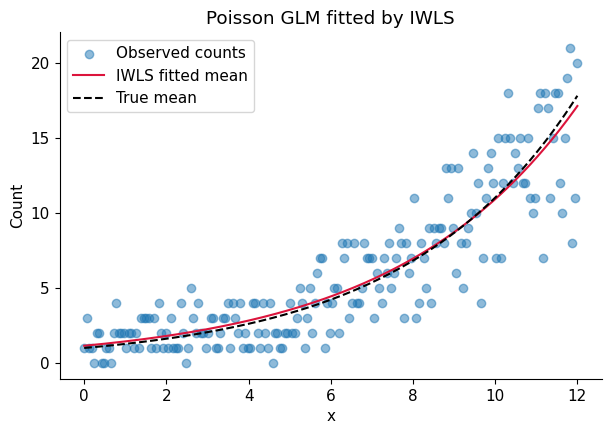

In [13]:
beta = np.zeros(2)
iteration_records = []
for iteration in range(25):
    eta = X @ beta
    mu = np.exp(eta)
    z = eta + (y - mu) / mu
    w = mu
    fit_wls = sm.WLS(z, X, weights=w).fit()
    beta_new = fit_wls.params
    step = np.max(np.abs(beta_new - beta))
    beta = beta_new
    iteration_records.append([iteration + 1, *beta, step])

history = pd.DataFrame(iteration_records,
                       columns=["iteration", "intercept", "slope", "max_step"])
mu_hat = np.exp(X @ beta)  # recompute at the final coefficient estimate
print("IWLS coefficients:", beta)
display(history.tail())

fig, ax = plt.subplots()
ax.scatter(x, y, alpha=0.5, label="Observed counts")
ax.plot(x, mu_hat, color="crimson", label="IWLS fitted mean")
ax.plot(x, mu_true, linestyle="--", color="black", label="True mean")
ax.set(xlabel="x", ylabel="Count", title="Poisson GLM fitted by IWLS")
ax.legend()
plt.show()

We can also compare the calculation with statsmodels' Poisson GLM fit.

In [14]:
fit_glm = sm.GLM(y, X, family=sm.families.Poisson()).fit()
display(pd.DataFrame({"True": beta_true, "IWLS": beta,
                      "statsmodels GLM": fit_glm.params},
                     index=["Intercept", "Slope"]))
np.testing.assert_allclose(beta, fit_glm.params, rtol=1e-7, atol=1e-8)

,True,IWLS,statsmodels GLM
Intercept,0.00,0.138140,0.138140
Slope,0.24,0.225234,0.225234


### Task 3
Explicitly compute the asymptotic variance-covariance matrix of $\widehat\beta$.

### Solution
The Fisher information is
$$J(\beta)=X^TW(\beta)X,$$
where $W(\beta)=\operatorname{diag}(\mu_1,\ldots,\mu_n)$. Under the usual regularity conditions,
$$\operatorname{Cov}(\widehat\beta)\approx J(\beta)^{-1}.$$
We estimate this using $J(\widehat\beta)^{-1}$. In NumPy, `mu_hat[:, None] * X` multiplies each row of `X` by its weight, avoiding an $n\times n$ diagonal matrix.

In [15]:
J_hat = X.T @ (mu_hat[:, None] * X)
cov_hat = np.linalg.solve(J_hat, np.eye(X.shape[1]))
labels = ["Intercept", "Slope"]
display(pd.DataFrame(cov_hat, index=labels, columns=labels))
print("Estimated standard errors:", np.sqrt(np.diag(cov_hat)))
np.testing.assert_allclose(cov_hat, fit_glm.cov_params(), rtol=1e-5, atol=1e-9)

,Intercept,Slope
Intercept,0.007765,-0.000820
Slope,-0.000820,0.000097


Estimated standard errors: [0.088118 0.009853]


## Sampling distribution of $\widehat\beta$
### Task 4
Investigate the sampling distribution of $\widehat\beta$ with the same fixed covariates. Compare the empirical variances and covariance with the inverse Fisher information.

### Solution
Simulate 10,000 independent datasets from the original true means and fit a Poisson GLM to each. This estimates the sampling distribution under $\beta_{\mathrm{true}}$. Its natural theoretical comparison is $J(\beta_{\mathrm{true}})^{-1}$. The fitted-data estimate $J(\widehat\beta)^{-1}$ will differ because it depends on the original random sample.

Using a separate random generator makes this simulation reproducible even if the initial data cell is rerun.

In [ ]:
rng_sim = np.random.default_rng(5601)
n_sim = 10_000  # reduce temporarily for a quick run
beta_mle = np.empty((n_sim, X.shape[1]))
for i in range(n_sim):
    y_sim = rng_sim.poisson(mu_true)
    fit_sim = sm.GLM(y_sim, X, family=sm.families.Poisson()).fit()
    if not fit_sim.converged:
        raise RuntimeError(f"Simulation {i} did not converge")
    beta_mle[i] = fit_sim.params

cov_empirical = np.cov(beta_mle, rowvar=False, ddof=1)
J_true = X.T @ (mu_true[:, None] * X)
cov_true = np.linalg.solve(J_true, np.eye(X.shape[1]))
display(pd.concat({
    "Empirical covariance": pd.DataFrame(cov_empirical, index=labels, columns=labels),
    "Inverse information at truth": pd.DataFrame(cov_true, index=labels, columns=labels),
    "Inverse information at fitted coefficients": pd.DataFrame(cov_hat, index=labels, columns=labels)
}))
display(pd.DataFrame({"True": beta_true, "Simulation mean": beta_mle.mean(axis=0),
                      "Empirical SD": beta_mle.std(axis=0, ddof=1),
                      "Asymptotic SD": np.sqrt(np.diag(cov_true))}, index=labels))

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for j, ax in enumerate(axes):
    ax.hist(beta_mle[:, j], bins=45, density=True, alpha=0.7)
    ax.axvline(beta_true[j], color="crimson", linestyle="--", label="True parameter")
    ax.set(xlabel=labels[j], ylabel="Density", title=f"Sampling distribution: {labels[j]}")
    ax.legend()
fig.tight_layout()
plt.show()

The empirical and theoretical covariance matrices should be close. They need not agree exactly: the information calculation is an asymptotic approximation, and the empirical covariance has Monte Carlo error.

## Existence of MLEs for the Poisson GLM
### Optional task
Identify the exceptional case in which the MLE does not exist for
$$Y_1,\ldots,Y_n\stackrel{\mathrm{iid}}\sim\operatorname{Poisson}(\lambda),
\qquad n\geq1,\quad\lambda>0.$$

### Solution
The likelihood is
$$L(\lambda)=\exp(-n\lambda)
\frac{\lambda^{\sum_i y_i}}{\prod_i y_i!}.$$
When $\sum_i y_i>0$, its maximum occurs at $\widehat\lambda=\bar y>0$.
If all counts are zero, $L(\lambda)=\exp(-n\lambda)$ is strictly decreasing. Its supremum is approached as $\lambda\downarrow0$, but is not attained in the specified parameter space $\lambda>0$. If zero were allowed, the MLE would be zero. Under a log link, the corresponding intercept tends to $-\infty$.

### Task 5
Suppose at least one observation has a zero count. Explain why there is no finite MLE if a predictor satisfies $x_{ij}=0$ whenever $y_i>0$, and $x_{ij}>0$ whenever $y_i=0$.

### Solution
The $j$th component of the score is
$$\frac{\partial\ell}{\partial\beta_j}
=\sum_i x_{ij}(y_i-\mu_i)
=-\sum_{i:y_i=0}x_{ij}\exp(\eta_i)<0.$$
Thus the score cannot vanish at any finite coefficient vector. Decreasing $\beta_j$ reduces the fitted means for zero counts and leaves the positive-count means unchanged, so the likelihood increases as $\beta_j\to-\infty$.

The sum is over the **zero counts**; the positive-count observations have $x_{ij}=0$.

## MLE existence
Write $u_i$ for the covariate vector **excluding the intercept**. Suppose the model includes an intercept, the design matrix has full column rank, and $S=\sum_i y_i>0$. A finite MLE exists if and only if
$$\bar u_y=\frac{\sum_i y_i u_i}{\sum_i y_i}$$
lies in the **relative interior of the convex hull** of the covariate vectors. The relative interior is the interior within the affine space spanned by the hull. For the two-dimensional example below, it is the ordinary interior of the polygon.

With positive counts at every observation, the weighted average lies in the relative interior. Zero counts allow it to lie on a boundary. The normalisation by $S$ is essential for this convex-hull statement.

The supplied tutorial credits a University of Copenhagen teaching example. We retain its four covariate points and response vectors here.

In [ ]:
U = np.array([[-2., 1.], [-1., -1.], [2., 0.], [0., 2.]])
X_small = np.column_stack([np.ones(len(U)), U])
hull = ConvexHull(U)

def plot_hull(y_counts, title):
    weighted_mean = (y_counts @ U) / y_counts.sum()
    polygon = U[hull.vertices]
    fig, ax = plt.subplots()
    ax.fill(polygon[:, 0], polygon[:, 1], alpha=0.2)
    ax.scatter(U[:, 0], U[:, 1], s=70, color="black")
    for point, count in zip(U, y_counts):
        ax.annotate(f"y = {count}", point, xytext=(6, 7), textcoords="offset points")
    ax.scatter(*weighted_mean, color="blue", s=90, label="Count-weighted mean", zorder=5)
    ax.set(xlabel="x1", ylabel="x2", title=title)
    ax.set_aspect("equal", adjustable="box")
    ax.margins(0.2)
    ax.legend()
    plt.show()
    return weighted_mean

y_interior = np.array([1, 2, 1, 0])
t_interior = plot_hull(y_interior, "A finite MLE: weighted mean inside the hull")
fit_interior = sm.GLM(y_interior, X_small, family=sm.families.Poisson()).fit()
print("Weighted mean:", t_interior)
display(pd.DataFrame({"Coefficient": fit_interior.params, "Standard error": fit_interior.bse},
                     index=["Intercept", "x1", "x2"]))

### Task 6
Replace the responses with $(1,2,0,0)$. Where is the count-weighted mean now? Explain why no finite coefficient vector maximises the likelihood.

### Solution
The weighted mean lies on the edge joining the first two points. We can keep their fitted means fixed and drive the other two means towards zero.

In [ ]:
y_boundary = np.array([1, 2, 0, 0])
t_boundary = plot_hull(y_boundary, "No finite MLE: weighted mean on an edge")
print("Weighted mean:", t_boundary)

A direct likelihood calculation makes the failure of existence visible without depending on a software convergence flag. Let
$$d=(-3,-2,-1)^T.$$
Then $X d=(0,0,-7,-5)^T$. Along $\beta(t)=\beta_{\mathrm{base}}+td$, the first two means remain fixed and the other two approach zero. Choose $\beta_{\mathrm{base}}$ so that the first two means are their observed counts, 1 and 2.

In [10]:
direction = np.array([-3., -2., -1.])
beta_base = np.array([2 * np.log(2), np.log(2), 0.])
np.testing.assert_allclose(X_small @ direction, [0, 0, -7, -5])

path_rows = []
for t in [0, 0.5, 1, 2, 4, 8]:
    beta_t = beta_base + t * direction
    eta_t = X_small @ beta_t
    mu_t = np.exp(eta_t)
    loglik = np.sum(y_boundary * eta_t - mu_t - gammaln(y_boundary + 1))
    path_rows.append([t, *beta_t, *mu_t, loglik])
path = pd.DataFrame(path_rows, columns=["t", "Intercept", "x1", "x2",
                                        "mu1", "mu2", "mu3", "mu4", "Log likelihood"])
display(path)
print("Limiting log likelihood:", -1 + 2 * np.log(2) - 2 - gammaln(3))

,t,Intercept,x1,x2,mu1,mu2,mu3,mu4,Log likelihood
0,0.0,1.386294,0.693147,0.0,1.0,2.0,1.600000e+01,4.000000e+00,-22.306853
1,0.5,-0.113706,-0.306853,-0.5,1.0,2.0,4.831581e-01,3.283400e-01,-3.118351
2,1.0,-1.613706,-1.306853,-1.0,1.0,2.0,1.459011e-02,2.695179e-02,-2.348395
3,2.0,-4.613706,-3.306853,-2.0,1.0,2.0,1.330446e-05,1.815997e-04,-2.307048
4,4.0,-10.613706,-7.306853,-4.0,1.0,2.0,1.106304e-11,8.244614e-09,-2.306853
5,8.0,-22.613706,-15.306853,-8.0,1.0,2.0,7.649429e-24,1.699342e-17,-2.306853


Limiting log likelihood: -2.3068528194400546


The log likelihood increases towards a finite supremum as the coefficients diverge. Every finite coefficient vector gives strictly positive means for the zero-count observations, so the supremum is never attained.

A numerical GLM fit may stop with large coefficients or standard errors, issue a warning, or declare convergence because changes in deviance have become tiny. These are numerical symptoms; the boundary geometry establishes that a finite MLE does not exist.
